# Phase 11 — SHAP Interpretation

**Purpose.** Explain *why* the final classifier accepts or rejects pairs, globally and for individual errors, and cross-check the Phase 9 permutation importance.
SHAP values are computed on the **actual** saved model (`model_pair.joblib`; scikit-learn HistGradientBoosting has no built-in TreeSHAP, so the model-agnostic `PermutationExplainer` is used on the model's probability output).
Nothing here changes the model or threshold.

**Sample.** 1,200 validation pairs: 600 true matches + 600 non-matches, with 300 of the non-matches taken from the highest-scoring (hard) ones; plus the false positives / rejected matches inspected in Phase 9 for the local explanations.

**Sections:** 1 Load → 2 SHAP values → 3 Global importance (vs permutation) → 4 Direction of effect → 5 Local explanations of errors → 6 Summary

In [1]:
import os, sys, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import pair_features as PF
ROOT = "../../../"; INTERIM = ROOT + "dataset/interim"
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 40)
FEATS = json.load(open("feature_list.json"))["final_features"]; THR = json.load(open("threshold_config.json"))["decision"]["threshold"]
cv = pd.read_pickle(INTERIM + "/candidates_val.pkl"); sv = pd.read_pickle(INTERIM + "/val_scores.pkl"); Fv = pd.read_pickle(INTERIM + "/features_val.pkl")[FEATS]
model = joblib.load("model_pair.joblib"); y = cv.label.values; p = sv.score.values
print(f"shap {shap.__version__} | {len(cv):,} validation pairs | threshold {THR}")

shap 0.53.0 | 227,888 validation pairs | threshold 0.7


## 2. Sample and compute SHAP values

In [2]:
rng = np.random.default_rng(42)
pos = rng.choice(np.where(y == 1)[0], 600, replace=False)
neg_all = np.where(y == 0)[0]; hard = neg_all[np.argsort(-p[neg_all])[:3000]]
neg = np.concatenate([rng.choice(hard, 300, replace=False), rng.choice(np.setdiff1d(neg_all, hard), 300, replace=False)])
fp_idx = np.where((p >= THR) & (y == 0))[0]; fn_idx = np.where((p < THR) & (y == 1))[0]
fp_sel = fp_idx[np.argsort(-p[fp_idx])[:3]]; fn_sel = fn_idx[np.argsort(-p[fn_idx])[:3]]
idx = np.unique(np.concatenate([pos, neg, fp_sel, fn_sel])); X = Fv.values.astype(np.float32)[idx]
bg = X[rng.choice(len(X), 100, replace=False)]
f = lambda A: model.predict_proba(np.asarray(A, np.float32))[:, 1]
expl = shap.PermutationExplainer(f, bg, max_evals=2 * len(FEATS) + 1, seed=42)
import time; t0 = time.time(); sh = expl(X, max_evals=2 * len(FEATS) + 1); S = sh.values
print(f"SHAP values {S.shape} in {time.time()-t0:.0f}s | additivity check: max |base + sum(shap) - p| = {np.abs(sh.base_values + S.sum(1) - f(X)).max():.3f}")

SHAP values (1206, 69) in 211s | additivity check: max |base + sum(shap) - p| = 0.002


## 3. Global importance, compared with permutation importance (Phase 9)

top 15 features by mean |SHAP| (probability units):
a_num_jacc           0.0791
a_tset               0.0596
n_ratio              0.0450
n_unm_c_max_idf      0.0339
a_tfidf_cos__rank    0.0323
n_soft_c             0.0312
n_partial            0.0294
a_idf_jacc           0.0274
n_unm_c_idf          0.0261
n_unm_c              0.0241
n_tsort              0.0226
n_tfidf_cos          0.0210
n_idf_jacc           0.0209
n_suf_conflict       0.0182
n_unm_s_max_idf      0.0181

top-8 overlap with permutation top-8: ['a_idf_jacc', 'a_num_jacc', 'a_tset', 'n_ratio', 'n_unm_c_max_idf']

mean total |SHAP| per feature group:
name_structural    0.291
name_basic         0.215
addr_basic         0.176
relative           0.172
addr_numbers       0.147


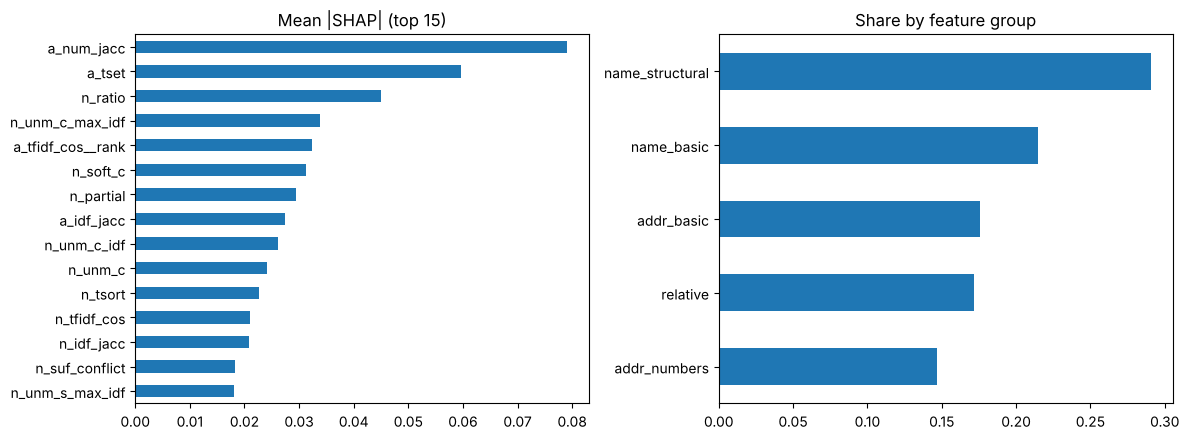

In [3]:
imp = pd.Series(np.abs(S).mean(0), index=FEATS).sort_values(ascending=False)
perm = pd.Series(json.load(open("phase9_summary.json"))["top_features"])
print("top 15 features by mean |SHAP| (probability units):"); print(imp.head(15).round(4).to_string())
print("\ntop-8 overlap with permutation top-8:", sorted(set(imp.head(8).index) & set(perm.index)))
grp = {g: [FEATS.index(c) for c in cols if c in FEATS] for g, cols in PF.GROUPS.items()}
gimp = pd.Series({g: np.abs(S[:, ix]).sum(1).mean() for g, ix in grp.items() if ix}).sort_values(ascending=False)
print("\nmean total |SHAP| per feature group:"); print((gimp / gimp.sum()).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); imp.head(15)[::-1].plot.barh(ax=ax[0]); ax[0].set_title("Mean |SHAP| (top 15)")
(gimp / gimp.sum())[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Share by feature group"); plt.tight_layout(); plt.show()

## 4. Direction of effect (beeswarm) and dependence on the top features

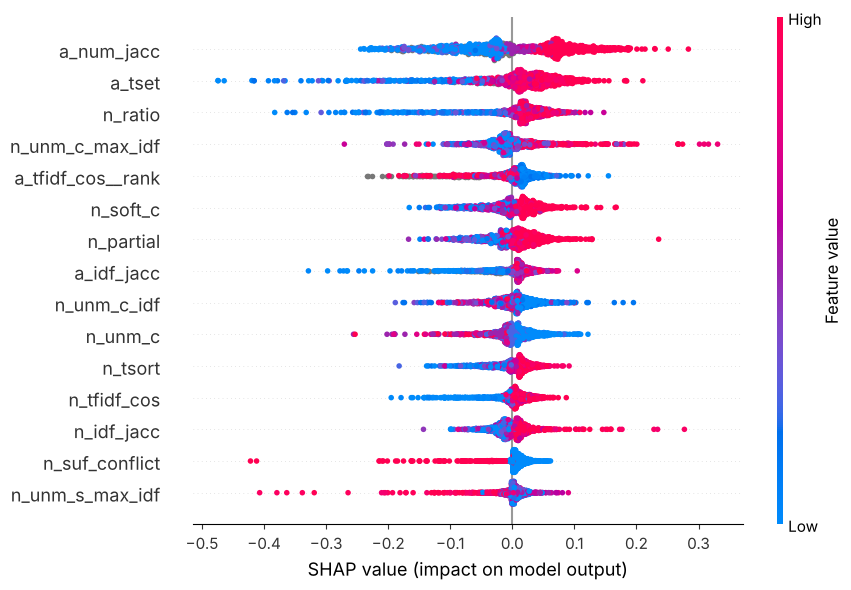

a_num_jacc: correlation(value, SHAP) = +0.85  (higher value -> more likely a match)
a_tset: correlation(value, SHAP) = +0.82  (higher value -> more likely a match)
n_ratio: correlation(value, SHAP) = +0.69  (higher value -> more likely a match)


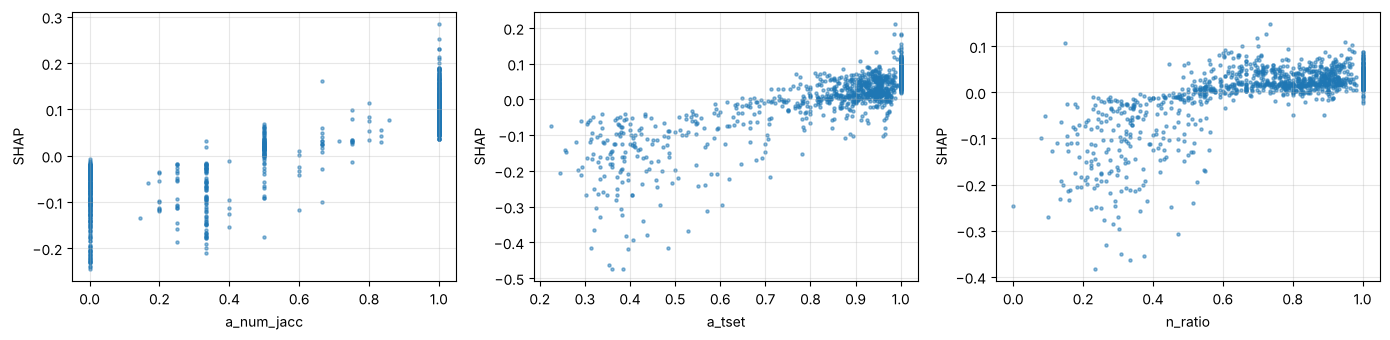

In [4]:
shap.summary_plot(S, X, feature_names=FEATS, max_display=15, show=False); plt.gcf().set_size_inches(9, 6); plt.tight_layout(); plt.show()
for ft in list(imp.index[:3]):
    j = FEATS.index(ft); v = X[:, j]; ok = ~np.isnan(v)
    c = np.corrcoef(v[ok], S[ok, j])[0, 1]; print(f"{ft}: correlation(value, SHAP) = {c:+.2f}  ({'higher value -> more likely a match' if c > 0 else 'higher value -> less likely a match'})")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, ft in zip(ax, imp.index[:3]): j = FEATS.index(ft); a.scatter(X[:, j], S[:, j], s=5, alpha=.5); a.set_xlabel(ft); a.set_ylabel("SHAP"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Local explanations — the confident false positives and the near-miss rejections from Phase 9

In [5]:
pos_of = {k: i for i, k in enumerate(idx)}
def explain(k, title):
    i = pos_of[k]; r = cv.iloc[k]; order = np.argsort(-np.abs(S[i]))[:6]
    print(f"\n{title}: p={p[k]:.3f} (base {sh.base_values[i]:.3f}) | {r.s1_name!r} vs {r.c_name!r} | {r.s1_addr!r} vs {r.c_addr!r}")
    print("  " + "; ".join(f"{FEATS[j]}={X[i, j]:.2f} ({S[i, j]:+.3f})" for j in order))
for k in fp_sel: explain(k, "FALSE POSITIVE")
for k in fn_sel: explain(k, "REJECTED TRUE MATCH")


FALSE POSITIVE: p=0.999 (base 0.559) | 'Garcia, Lisetta C., DDS' vs 'Garcia, Lisetta C., BDDS' | '9109 Windrush Drive, Fort Worth, TX' vs '9109. WINDRUSH DR, FORT WORTH, TX'
  a_num_jacc=1.00 (+0.103); a_tset=1.00 (+0.087); n_tsort=0.88 (+0.028); n_unm_c_max_idf=14.16 (+0.022); a_partial=1.00 (+0.019); n_jw=0.99 (+0.018)

FALSE POSITIVE: p=0.998 (base 0.559) | 'Onyx' vs 'Onyxwex' | '207 Jay Street, Ithaca, NY' vs '207 Aurora St, Ithaca, New York'
  a_num_jacc=1.00 (+0.073); a_tset=0.83 (+0.073); a_first_num_eq=1.00 (+0.035); n_partial=1.00 (+0.034); n_len_c=7.00 (+0.031); a_partial=0.79 (+0.029)

FALSE POSITIVE: p=0.998 (base 0.559) | 'Jalandhar In' vs 'jalandharlegal.com' | '# 1063, Urban Estate Phase-1, Jalandhar, Punjab' vs '812 URBAN ESTATE PHASE 1, JALANDHAR, Punjab'
  n_jacc=0.00 (+0.120); n_unm_c_max_idf=14.86 (+0.104); c_domain_style=1.00 (+0.083); n_ratio=0.69 (+0.059); n_unm_s_max_idf=11.07 (-0.042); a_tset=0.95 (+0.031)

REJECTED TRUE MATCH: p=0.699 (base 0.559) | 'Metro Ch

## 6. Summary

In [6]:
out = {"top_features_shap": imp.head(10).round(4).to_dict(), "group_share": (gimp / gimp.sum()).round(3).to_dict(), "n_explained": int(len(idx)),
       "overlap_with_permutation_top8": sorted(set(imp.head(8).index) & set(perm.index))}
json.dump(out, open("phase11_summary.json", "w"), indent=2); print(json.dumps(out, indent=2))

{
  "top_features_shap": {
    "a_num_jacc": 0.0791,
    "a_tset": 0.0596,
    "n_ratio": 0.045,
    "n_unm_c_max_idf": 0.0339,
    "a_tfidf_cos__rank": 0.0323,
    "n_soft_c": 0.0312,
    "n_partial": 0.0294,
    "a_idf_jacc": 0.0274,
    "n_unm_c_idf": 0.0261,
    "n_unm_c": 0.0241
  },
  "group_share": {
    "name_structural": 0.291,
    "name_basic": 0.215,
    "addr_basic": 0.176,
    "relative": 0.172,
    "addr_numbers": 0.147
  },
  "n_explained": 1206,
  "overlap_with_permutation_top8": [
    "a_idf_jacc",
    "a_num_jacc",
    "a_tset",
    "n_ratio",
    "n_unm_c_max_idf"
  ]
}
